In [123]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import os, glob
import pandas as pd

In [124]:
import matplotlib as mpl
import matplotlib.font_manager as fm

FONT_DIR = os.path.expanduser("~/fonts/SourceSans3")

for f in glob.glob(os.path.join(FONT_DIR, "*.ttf")):
    fm.fontManager.addfont(f)

available = {f.name for f in fm.fontManager.ttflist}
FAMILY = next((n for n in ("Source Sans 3", "Source Sans Pro") if n in available), None)
if FAMILY is None:
    raise RuntimeError(f"Source Sans not found. Check FONT_DIR: {FONT_DIR}")

W = 418.25372 / 72.27   # \textwidth in inches (~5.787)
W_HALF = 0.48 * W       # two panels side by side

mpl.rcParams.update({
    # --- Text / fonts ---
    "text.usetex": False,
    "font.family": "sans-serif",
    "font.sans-serif": [FAMILY],
    "mathtext.fontset": "custom",
    "mathtext.rm": FAMILY,
    "mathtext.it": f"{FAMILY}:italic",
    "mathtext.bf": f"{FAMILY}:bold",
    "mathtext.sf": FAMILY,
    "mathtext.default": "it",
    "mathtext.fallback": "cm",     
    "axes.unicode_minus": True,    

    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.titlesize": 10,

    "axes.linewidth": 0.8,
    "lines.linewidth": 1.3,
    "lines.markersize": 4,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3.5,
    "ytick.major.size": 3.5,
    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,
    "xtick.minor.size": 2,
    "ytick.minor.size": 2,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "grid.linewidth": 0.5,
    "grid.alpha": 0.4,

    "legend.frameon": False,
    "legend.handlelength": 1.5,

    "figure.figsize": (W, W),
    "figure.constrained_layout.use": True,
    "savefig.dpi": 300,             
    "savefig.format": "pdf",
    "pdf.fonttype": 42,    
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

In [125]:
run = '2024/oper_08'
reference_years = np.arange(1991, 1996, 1)
release = 2

In [126]:
path = '/jetfs/scratch/psplechtna/thesisdata/oper/'

In [127]:
data = xr.open_dataset(path+run+'_temporal_evol.nc')
data_tsr = xr.open_dataset(path+run+'_tsr.nc')
reference = xr.open_mfdataset([path+f'1991-2020/{year}_temporal_evol.nc' for year in reference_years])
ref_tsr = xr.open_mfdataset([path+f'1991-2020/{year}_tsr.nc' for year in reference_years])

In [128]:
reference_mean = reference.mean(dim='release_time')
reference_std = reference.std(dim='release_time')

In [129]:
data = data.isel(release_time=release)
data_tsr = data_tsr.isel(release_date=release)

In [130]:
t_release=pd.Timestamp(data.release_time.values)

In [131]:
data['tot_anom'] = data.flux_lh + data.flux_sh + data.advection + data.rad_sw + data.rad_lw + data.seasonality + data_tsr.init_anomaly

findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive
findfont: Failed to find font weight bold for Source Sans 3, now using 400.


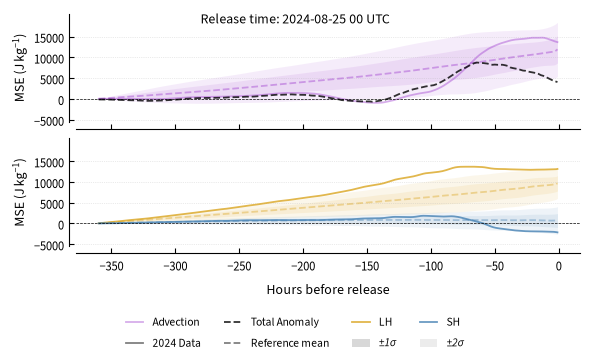

In [132]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

def plot_var(ax, name, color, label, alpha=0.8):
    m, s = reference_mean[name], reference_std[name]
    ax.plot(xes, data[name], color=color, ls='-', alpha=alpha, label=label)
    ax.plot(xes, m, color=color, ls='--', alpha=0.4)
    for n, a in [(1, 0.1), (2, 0.09)]:
        ax.fill_between(xes, m - n*s, m + n*s, color=color, alpha=a, linewidth=0)

xes = data.lag
fig, ax = plt.subplots(2, 1, figsize=(W, 0.6*W), sharex=True)

plot_var(ax[0], 'advection', 'darkorchid', 'Advection', alpha=0.4)
plot_var(ax[1], 'flux_lh', 'goldenrod', 'LH')
plot_var(ax[1], 'flux_sh', 'steelblue', 'SH')

ax[0].plot(xes, data.tot_anom, color='k', linestyle='--', alpha=0.8, label='Total Anomaly')

# one entry per color (collected from both axes)
handles, labels = [], []
for a in ax:
    h, l = a.get_legend_handles_labels()
    handles += h; labels += l
    a.grid(ls=':', alpha=0.5, axis='y')
    a.axhline(0, color='k', ls='--', lw=0.5)
    a.set_ylim(-5500, 20500)
    a.set_yticks(np.arange(-5000, 20000, 5000))
    a.set_ylabel(r'MSE ($\mathrm{J\,kg^{-1}}$)')
    for spine in ['top', 'right']:
        a.spines[spine].set_visible(False)
    spine_offset = 5
    a.spines.left.set_position(('outward', spine_offset))
    a.spines.bottom.set_position(('outward', spine_offset))

ax[1].set_xlabel('Hours before release')

# one entry per style, in neutral gray
style_handles = [
    Line2D([], [], color='gray', ls='-',  label='2024 Data'),
    Line2D([], [], color='gray', ls='--', label='Reference mean'),
    Patch(facecolor='gray', alpha=0.30, label=r'$\pm 1\sigma$'),
    Patch(facecolor='gray', alpha=0.15, label=r'$\pm 2\sigma$'),
]
all_handles = handles + style_handles
ncol = 4
reordered = [h for i in range(ncol) for h in all_handles[i::ncol]]

fig.suptitle(f'Release time: {t_release:%Y-%m-%d %H} UTC', y=1)
fig.legend(handles=reordered, ncol=ncol, fontsize='small',
             loc='outside lower center')
#fig.savefig('plots/temporal_evol.pdf')

## variance decomposition

flux_lh      max|C(lag=-1) - total| = 0   (std of total = 1.8e+03)
flux_sh      max|C(lag=-1) - total| = 0   (std of total = 1.67e+03)
advection    max|C(lag=-1) - total| = 0   (std of total = 3.25e+03)
seasonality  max|C(lag=-1) - total| = 0   (std of total = 2.56e+03)
beta_init = 0.11; sum at lag=-1: 1.000 (should be 1)


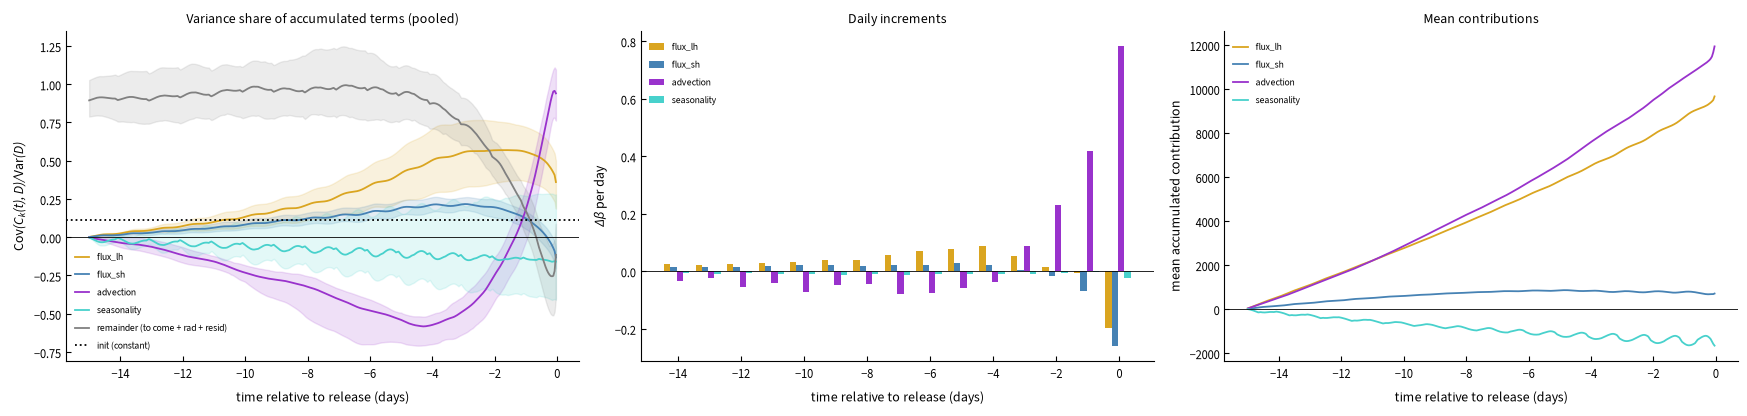

In [138]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

terms_t = ["flux_lh", "flux_sh", "advection", "seasonality"]

ref = reference.drop_vars(["expver", "number"], errors="ignore").sortby("lag")

# align the two datasets (release_time vs release_date)
assert (ref["release_time"].values == ref_tsr["release_date"].values).all(), "release times differ"
D    = ref_tsr["diag_anomaly"].values.astype(float)
init = ref_tsr["init_anomaly"].values.astype(float)
years = pd.DatetimeIndex(ref["release_time"].values).year.values

C = np.stack([ref[v].values for v in terms_t], axis=-1).astype(float)   # (n, 360, 4), cumulative from t0
assert not np.isnan(C).any(), "NaNs in terms: decide how to handle them"
lag_d = ref["lag"].values / 24                                          # -15 ... ~0 days

# consistency with the scalar totals (cumulative value at lag = -1)
for k, v in enumerate(terms_t):
    tot = ref_tsr[v].values.astype(float)
    print(f"{v:12s} max|C(lag=-1) - total| = {np.abs(C[:, -1, k] - tot).max():.3g}"
          f"   (std of total = {tot.std():.3g})")

def transform(x, yrs, mode):
    uy = np.unique(yrs)
    if mode == "pooled":
        return x
    if mode == "between":                      # one value per summer
        return np.stack([x[yrs == y].mean(0) for y in uy])
    x = x.astype(float).copy()                 # "within": deviations from each summer's own mean
    for y in uy:
        x[yrs == y] -= x[yrs == y].mean(0)
    return x

def decomp(C, D, init, yrs, mode="pooled"):
    Cm, Dm, Im = (transform(a, yrs, mode) for a in (C, D, init))
    rem = Dm[:, None] - Im[:, None] - Cm.sum(-1)           # (n, lag)
    Dc = Dm - Dm.mean()
    ddof = len(Dc) - 1
    var = Dc @ Dc / ddof
    beta      = np.einsum("n,ntk->tk", Dc, Cm - Cm.mean(0)) / ddof / var
    beta_rem  = (Dc @ (rem - rem.mean(0))) / ddof / var
    beta_init = (Dc @ (Im - Im.mean())) / ddof / var
    return beta, beta_rem, beta_init

def year_bootstrap(C, D, init, yrs, mode, nboot=2000, seed=0):
    rng = np.random.default_rng(seed)
    uy = np.unique(yrs)
    groups = {y: np.where(yrs == y)[0] for y in uy}
    out = []
    for _ in range(nboot):
        ys = rng.choice(uy, len(uy), replace=True)
        idx = np.concatenate([groups[y] for y in ys])
        lab = np.concatenate([np.full(len(groups[y]), i) for i, y in enumerate(ys)])
        b, br, _ = decomp(C[idx], D[idx], init[idx], lab, mode)
        out.append(np.concatenate([b, br[:, None]], axis=1))
    return np.percentile(out, [2.5, 97.5], axis=0)         # (2, lag, k+1)

mode = "pooled"                                            # "pooled" | "between" | "within"
beta, beta_rem, beta_init = decomp(C, D, init, years, mode)
names = terms_t + ["remainder (to come + rad + resid)"]
B = np.concatenate([beta, beta_rem[:, None]], axis=1)
print(f"beta_init = {beta_init:.2f}; sum at lag=-1: {B[-1].sum() + beta_init:.3f} (should be 1)")

ci = year_bootstrap(C, D, init, years, mode) if len(np.unique(years)) >= 2 else None

colors = {
    "flux_lh":    "goldenrod",
    "flux_sh":    "steelblue",
    "advection":  "darkorchid",
    "seasonality":"mediumturquoise",
    "remainder (to come + rad + resid)": "grey",
}

fig, ax = plt.subplots(1, 3, figsize=(3*W, 0.7*W), constrained_layout=True)

# (a) beta vs. lag
for k, n in enumerate(names):
    ax[0].plot(lag_d, B[:, k], label=n, color=colors[n])
    if ci is not None:
        ax[0].fill_between(lag_d, ci[0, :, k], ci[1, :, k], alpha=.15, color=colors[n])
ax[0].axhline(beta_init, color="k", ls=":", label="init (constant)")
ax[0].axhline(0, color="k", lw=.6)
ax[0].set_xlabel("time relative to release (days)")
ax[0].set_ylabel(r"$\mathrm{Cov}(C_k(t), D)/\mathrm{Var}(D)$")
ax[0].set_title(f"Variance share of accumulated terms ({mode})"); ax[0].legend(fontsize=7)

# (b) daily increments of beta
spd = 24
inc = (B[spd - 1::spd] - np.vstack([np.zeros((1, B.shape[1])), B[spd - 1::spd][:-1]]))[:, :len(terms_t)]
days = lag_d[spd - 1::spd]
w = 0.8 / len(terms_t)
for k, n in enumerate(terms_t):
    ax[1].bar(days + (k - len(terms_t)/2 + .5) * w, inc[:, k], w, label=n, color=colors[n])
ax[1].axhline(0, color="k", lw=.6)
ax[1].set_xlabel("time relative to release (days)"); ax[1].set_ylabel(r"$\Delta\beta$ per day")
ax[1].set_title("Daily increments"); ax[1].legend(fontsize=7)

# (c) mean accumulated contribution
for k, n in enumerate(terms_t):
    ax[2].plot(lag_d, C[..., k].mean(0), label=n, color=colors[n])
ax[2].axhline(0, color="k", lw=.6)
ax[2].set_xlabel("time relative to release (days)"); ax[2].set_ylabel("mean accumulated contribution")
ax[2].set_title("Mean contributions"); ax[2].legend(fontsize=7)
plt.show()

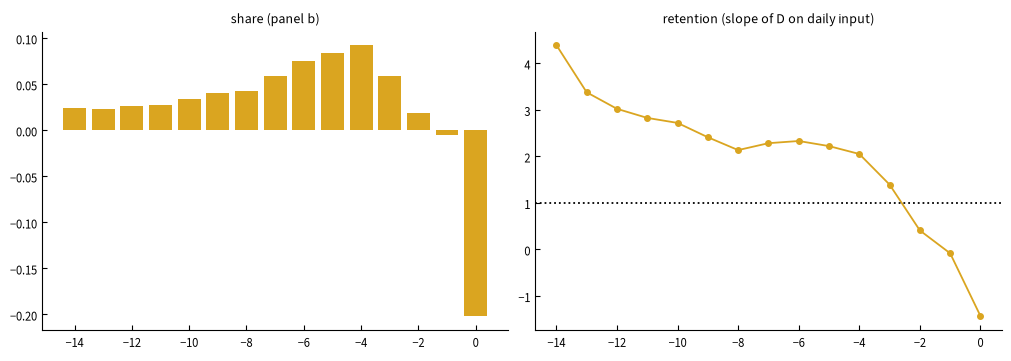

In [134]:
spd = 24
Cd = C[:, spd-1::spd, :]                                   # (n, ndays, k): cumulative at end of each day
dC = np.diff(Cd, axis=1, prepend=np.zeros_like(Cd[:, :1])) # daily input per term

dCm, Dm = transform(dC, years, mode), transform(D, years, mode)
Dc = Dm - Dm.mean()
dCc = dCm - dCm.mean(0)
n = len(Dc)

cov   = np.einsum("n,ntk->tk", Dc, dCc) / (n - 1)
varIn = (dCc**2).sum(0) / (n - 1)
share = cov / (Dc @ Dc / (n - 1))                          # = panel (b)
retention = cov / varIn                                    # slope of D on daily input

k = terms_t.index("flux_lh")
days = np.arange(1, Cd.shape[1] + 1) - Cd.shape[1]         # -15 ... -1
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
ax[0].bar(days, share[:, k], color="goldenrod"); ax[0].set_title("share (panel b)")
ax[1].plot(days, retention[:, k], "o-", color="goldenrod"); ax[1].axhline(1, color="k", ls=":")
ax[1].set_title("retention (slope of D on daily input)")
plt.show()

In [135]:
# transform(), mode, years, terms_t, dC (n, ndays, k), D (n,), init (n,) as before
dCm = transform(dC, years, mode);    dCc = dCm - dCm.mean(0)
Dm  = transform(D, years, mode);     Dc  = Dm - Dm.mean()
Im  = transform(init, years, mode);  Ic  = Im - Im.mean()
n = len(Dc)

k = terms_t.index("flux_lh")
x = dCc[:, :, k]                                   # (n, ndays) input of the term of interest
tot = dCc.sum(1)                                   # (n, k) total accumulation per term
rem = Dc - Ic - tot.sum(1)                         # remainder: radiation + budget residual

others = {                                         # each (n,), time-independent
    "init": Ic,
    "remainder": rem,
    **{t: tot[:, j] for j, t in enumerate(terms_t) if j != k},
}
same_term_other_days = tot[:, [k]] - x             # (n, ndays), depends on the day

varIn = (x**2).sum(0) / (n - 1)
r = (Dc @ x) / (n - 1) / varIn
print("Var(input) per day:", varIn.round(3))

total_excess = np.zeros_like(r)
for name, X in others.items():
    excess = (x * X[:, None]).sum(0) / (n - 1) / varIn      # no summing over days here
    total_excess += excess
    print(f"{name:22s}", excess.round(2))

excess = (x * same_term_other_days).sum(0) / (n - 1) / varIn   # elementwise, per day
total_excess += excess
print(f"{'same term, other days':22s}", excess.round(2))

print("check, 1 + sum(excess) - r (should be ~0):", (1 + total_excess - r).round(6))

Var(input) per day: [ 21028.008  26816.153  33772.243  38253.226  48773.719  65859.567
  77321.6   100951.948 126099.16  147051.895 175686.453 166003.16
 184185.022 248813.86  547911.01 ]
init                   [-3.46 -3.03 -2.06 -1.47 -0.92 -0.55 -0.51 -0.47 -0.29 -0.25 -0.13 -0.04
  0.06 -0.06  0.06]
remainder              [-1.86 -2.57 -2.23 -2.51 -1.72 -1.65 -1.27 -1.16 -0.24  0.25 -0.08  0.31
  1.08  0.67  1.03]
flux_sh                [-2.73 -2.27 -2.16 -1.88 -1.35 -1.12 -1.02 -0.98 -0.6  -0.55 -0.4  -0.04
  0.45  0.78  0.83]
advection              [ 9.06  7.72  6.32  5.1   3.73  3.04  2.22  2.23  1.66  1.14  1.02 -0.36
 -1.97 -1.54 -2.02]
seasonality            [-0.46 -0.41 -0.82 -0.7  -1.16 -1.   -0.81 -0.65 -1.18 -1.09 -0.52 -0.3
 -0.19 -0.46 -0.75]
same term, other days  [ 2.84  2.93  2.97  3.29  3.15  2.7   2.53  2.31  1.97  1.71  1.16  0.82
 -0.02 -0.47 -1.59]
check, 1 + sum(excess) - r (should be ~0): [-0.  0. -0.  0. -0. -0.  0.  0.  0. -0.  0. -0.  0. -0.  0.]


In [136]:
# dCc: (n, ndays, k) centred daily inputs, Dc centred D (transformed per `mode`)
# others: dict name -> centred array (n,) for init, or (n, ndays) for the other terms' daily input
k = terms_t.index("flux_lh")
varIn = (dCc[:, :, k]**2).sum(0) / (n - 1)
print("Var(input) per day:", varIn.round(3))
for name, X in others.items():
    X = X if X.ndim == 2 else X[:, None]
    # contribution of X (summed over its time axis) to the excess of r over 1
    excess = (dCc[:, :, k] * X.sum(1, keepdims=True)).sum(0) / (n - 1) / varIn
    print(f"{name:12s}", excess.round(2))

Var(input) per day: [ 21028.008  26816.153  33772.243  38253.226  48773.719  65859.567
  77321.6   100951.948 126099.16  147051.895 175686.453 166003.16
 184185.022 248813.86  547911.01 ]
init         [-3.46 -3.03 -2.06 -1.47 -0.92 -0.55 -0.51 -0.47 -0.29 -0.25 -0.13 -0.04
  0.06 -0.06  0.06]
remainder    [-1.86 -2.57 -2.23 -2.51 -1.72 -1.65 -1.27 -1.16 -0.24  0.25 -0.08  0.31
  1.08  0.67  1.03]
flux_sh      [-2.73 -2.27 -2.16 -1.88 -1.35 -1.12 -1.02 -0.98 -0.6  -0.55 -0.4  -0.04
  0.45  0.78  0.83]
advection    [ 9.06  7.72  6.32  5.1   3.73  3.04  2.22  2.23  1.66  1.14  1.02 -0.36
 -1.97 -1.54 -2.02]
seasonality  [-0.46 -0.41 -0.82 -0.7  -1.16 -1.   -0.81 -0.65 -1.18 -1.09 -0.52 -0.3
 -0.19 -0.46 -0.75]
